In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/customer_churn_dataset-testing-master.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (64374, 12)


In [3]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

# Remove identifier feature
if "CustomerID" in X.columns:
    X = X.drop("CustomerID", axis=1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (64374, 10)
Target shape: (64374,)

Features:
['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']

Target distribution:
Churn
0    33881
1    30493
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (51499, 10)
Testing set shape: (12875, 10)

Training target distribution:
Churn
0    27105
1    24394
Name: count, dtype: int64

Testing target distribution:
Churn
0    6776
1    6099
Name: count, dtype: int64


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("\nTraining data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Numerical features:
['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']

Training data after preprocessing: (51499, 15)
Testing data after preprocessing: (12875, 15)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV

# Define Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Define hyperparameter search space
logistic_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"],
    "class_weight": [None, "balanced"]
}

# Randomized search
logistic_search = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=logistic_param_grid,
    n_iter=10,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

# Perform tuning
logistic_search.fit(X_train_processed, y_train)

print("Best Logistic Regression parameters:")
print(logistic_search.best_params_)

print("\nBest cross-validation F1-score:")
print(logistic_search.best_score_)

Best Logistic Regression parameters:
{'solver': 'lbfgs', 'class_weight': 'balanced', 'C': 0.01}

Best cross-validation F1-score:
0.820459417360933


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Define Random Forest model
rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Define hyperparameter search space
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Randomized search
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=10,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

# Perform tuning
rf_search.fit(X_train_processed, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F1-score:")
print(rf_search.best_score_)

Best Random Forest parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 30}

Best cross-validation F1-score:
0.9976798199878756


In [9]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

# Define XGBoost model
xgb_model = XGBClassifier(
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Define hyperparameter search space
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

# Randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=10,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

# Perform tuning
xgb_search.fit(X_train_processed, y_train)

print("Best XGBoost parameters:")
print(xgb_search.best_params_)

print("\nBest cross-validation F1-score:")
print(xgb_search.best_score_)

Best XGBoost parameters:
{'subsample': 0.8, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 0.8}

Best cross-validation F1-score:
0.9999385082091025


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get the best tuned models
best_logistic = logistic_search.best_estimator_
best_rf = rf_search.best_estimator_
best_xgb = xgb_search.best_estimator_

# Generate predictions
logistic_pred = best_logistic.predict(X_test_processed)
rf_pred = best_rf.predict(X_test_processed)
xgb_pred = best_xgb.predict(X_test_processed)

# Generate probabilities for ROC-AUC
logistic_prob = best_logistic.predict_proba(X_test_processed)[:, 1]
rf_prob = best_rf.predict_proba(X_test_processed)[:, 1]
xgb_prob = best_xgb.predict_proba(X_test_processed)[:, 1]

# Convert target labels to 0 and 1 if required
if y_test.dtype == "object":
    y_test_binary = y_test.map({"No": 0, "Yes": 1})
else:
    y_test_binary = y_test

# Function to calculate metrics
def evaluate_model(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Evaluate tuned models
logistic_metrics = evaluate_model(
    y_test_binary,
    logistic_pred,
    logistic_prob
)

rf_metrics = evaluate_model(
    y_test_binary,
    rf_pred,
    rf_prob
)

xgb_metrics = evaluate_model(
    y_test_binary,
    xgb_pred,
    xgb_prob
)

# Create comparison table
tuned_results = pd.DataFrame(
    [logistic_metrics, rf_metrics, xgb_metrics],
    index=[
        "Tuned Logistic Regression",
        "Tuned Random Forest",
        "Tuned XGBoost"
    ]
)

print("Tuned Model Performance:")
display(tuned_results.round(4))

Tuned Model Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Tuned Logistic Regression,0.8264,0.8039,0.838,0.8206,0.9029
Tuned Random Forest,0.9983,0.9993,0.997,0.9982,1.0000
Tuned XGBoost,1.0000,1.0000,1.000,1.0000,1.0000


In [11]:
# Get predicted probabilities from the tuned models

logistic_prob = best_logistic.predict_proba(X_test_processed)[:, 1]
rf_prob = best_rf.predict_proba(X_test_processed)[:, 1]
xgb_prob = best_xgb.predict_proba(X_test_processed)[:, 1]

# Equal weights for the three tuned models
weight_logistic = 1 / 3
weight_rf = 1 / 3
weight_xgb = 1 / 3

# Calculate hybrid ensemble probability
ensemble_probability = (
    weight_logistic * logistic_prob +
    weight_rf * rf_prob +
    weight_xgb * xgb_prob
)

# Convert probability into binary prediction
ensemble_prediction = (ensemble_probability >= 0.5).astype(int)

print("Tuned Hybrid Ensemble created successfully!")
print("Number of predictions:", len(ensemble_prediction))

Tuned Hybrid Ensemble created successfully!
Number of predictions: 12875


In [13]:
# Evaluate the tuned hybrid ensemble

ensemble_metrics = evaluate_model(
    y_test_binary,
    ensemble_prediction,
    ensemble_probability
)

print("Tuned Hybrid Ensemble Performance:")

for metric, value in ensemble_metrics.items():
    print(f"{metric}: {value:.4f}")

Tuned Hybrid Ensemble Performance:
Accuracy: 0.9991
Precision: 0.9997
Recall: 0.9985
F1-Score: 0.9991
ROC-AUC: 1.0000


In [14]:
# Add tuned Hybrid Ensemble results
tuned_results.loc["Tuned Hybrid Ensemble"] = ensemble_metrics

# Display final comparison
print("Final Tuned Model Comparison:")
display(tuned_results.round(4))

Final Tuned Model Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Tuned Logistic Regression,0.8264,0.8039,0.8380,0.8206,0.9029
Tuned Random Forest,0.9983,0.9993,0.9970,0.9982,1.0000
Tuned XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000
Tuned Hybrid Ensemble,0.9991,0.9997,0.9985,0.9991,1.0000


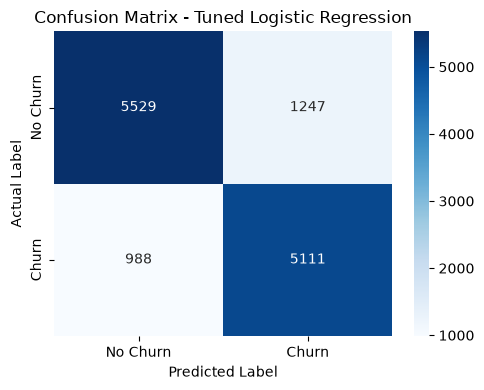

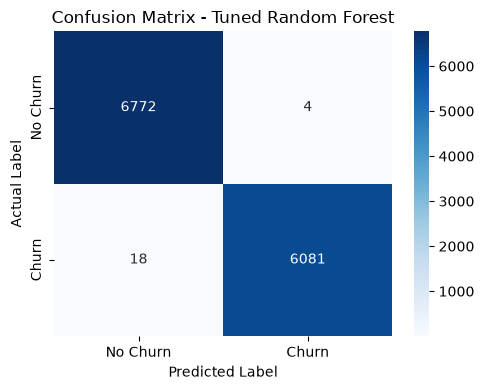

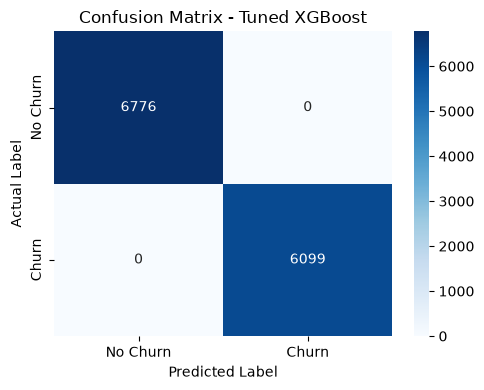

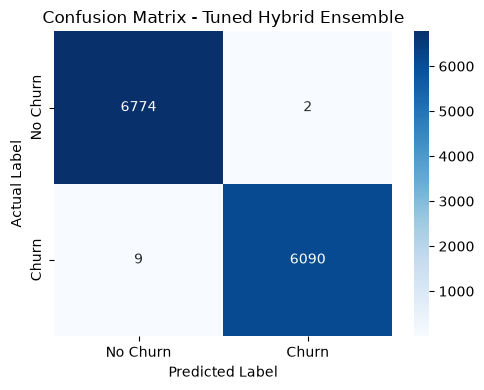

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Store model predictions
tuned_predictions = {
    "Tuned Logistic Regression": logistic_pred,
    "Tuned Random Forest": rf_pred,
    "Tuned XGBoost": xgb_pred,
    "Tuned Hybrid Ensemble": ensemble_prediction
}

# Plot confusion matrices
for model_name, predictions in tuned_predictions.items():

    cm = confusion_matrix(y_test_binary, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

In [16]:
from sklearn.metrics import classification_report

# Generate classification reports for all tuned models

for model_name, predictions in tuned_predictions.items():

    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        classification_report(
            y_test_binary,
            predictions,
            target_names=["No Churn", "Churn"]
        )
    )

Tuned Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.82      0.83      6776
       Churn       0.80      0.84      0.82      6099

    accuracy                           0.83     12875
   macro avg       0.83      0.83      0.83     12875
weighted avg       0.83      0.83      0.83     12875

Tuned Random Forest
              precision    recall  f1-score   support

    No Churn       1.00      1.00      1.00      6776
       Churn       1.00      1.00      1.00      6099

    accuracy                           1.00     12875
   macro avg       1.00      1.00      1.00     12875
weighted avg       1.00      1.00      1.00     12875

Tuned XGBoost
              precision    recall  f1-score   support

    No Churn       1.00      1.00      1.00      6776
       Churn       1.00      1.00      1.00      6099

    accuracy                           1.00     12875
   macro avg       1.00      1.00      1.00     12875
weighted avg  

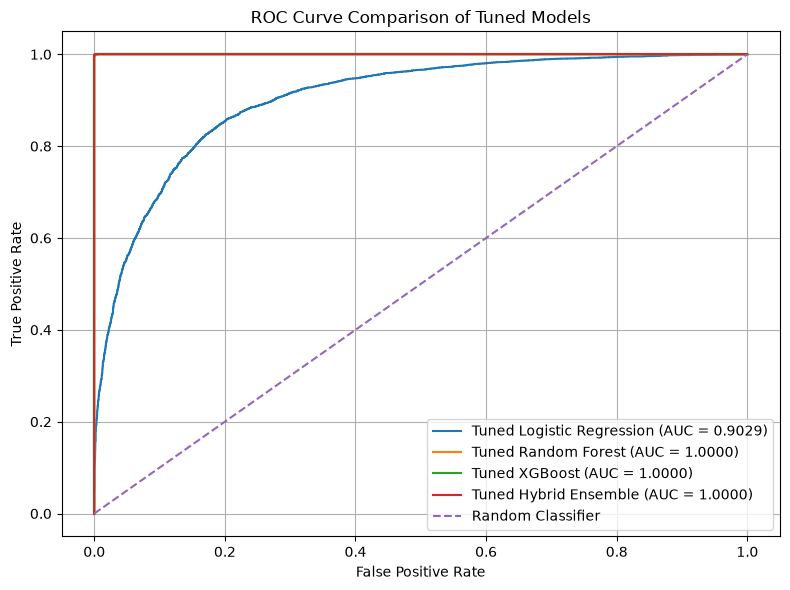

In [17]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test_binary, logistic_prob
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test_binary, rf_prob
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test_binary, xgb_prob
)

fpr_ensemble, tpr_ensemble, _ = roc_curve(
    y_test_binary, ensemble_probability
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Tuned Logistic Regression (AUC = {logistic_metrics['ROC-AUC']:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Tuned Random Forest (AUC = {rf_metrics['ROC-AUC']:.4f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"Tuned XGBoost (AUC = {xgb_metrics['ROC-AUC']:.4f})"
)

plt.plot(
    fpr_ensemble,
    tpr_ensemble,
    label=f"Tuned Hybrid Ensemble (AUC = {ensemble_metrics['ROC-AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Tuned Models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Display the best hyperparameters and cross-validation scores

tuning_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Best Parameters": [
        logistic_search.best_params_,
        rf_search.best_params_,
        xgb_search.best_params_
    ],
    "Best CV F1-Score": [
        logistic_search.best_score_,
        rf_search.best_score_,
        xgb_search.best_score_
    ]
})

print("Hyperparameter Tuning Summary:")
display(tuning_summary)

In [ ]:
print("Final Tuned Model Results:")
display(tuned_results.round(4))

In [ ]:
# Display final tuned results for reference

print("==============================================")
print("FINAL TUNED MODEL RESULTS")
print("==============================================")

display(tuned_results.round(4))

print("\nNotebook 06 - Hyperparameter Tuning completed successfully!")